# CS781 Capstone · Phase 7
## Prior Case Retrieval

**Scope** · Gold-supervised retrieval using the Phase 1 legal backbones and the original 16k BPE vocabulary.

Each query and candidate is encoded separately. A shared document head combines up to four windows into one normalized vector, and cosine similarity ranks the corresponding split's candidate pool. The notebook selects weights by Dev Micro-F1@7 and exports seven distinct case IDs per test query.

| Preset | Phase 1 adaptation | Experiment |
|---|---|---|
| `decoder` | Upper two blocks, final normalization and retrieval head | Partial fine-tuning |
| `encoder_decoder` | IA³ scales on key, value and feed-forward activations plus the head | Parameter-efficient adaptation |
| `prefix` | Rank-8 output-side LoRMA+ plus the head | Required LoRMA-family experiment |
| `efficient` | Fully trained compact model retaining original blocks 0, 7 and 15 | Gold-only student control |

The best larger checkpoints are retained for the subsequent distillation experiment. The gold student measures the compact architecture under the same gold supervision.

### Kaggle inputs

Mount the [prepared PCR bundle](phase7_preparation.ipynb) and the matching original Phase 1 checkpoint. Set `PREPARED_INPUT` and `PHASE1_CHECKPOINT` to the mounted paths as needed. Set `RECOVERY_INPUT` to the expanded dense run directory when resuming in a new session. Continue to [encoder-decoder reranking](phase7_rerank_encoder_decoder.ipynb) for the final predictions and the KD teacher input.


## 1. Kaggle configuration

Create one session per preset and select **GPU T4 ×2**. Attach the Phase 7 prepared ZIP or expanded bundle, the chosen original Phase 1 checkpoint and, when available, the official `evaluate_phase7.py`. The prepared bundle already holds the packed tokens and split metadata. Internet access can stay off.

| `ARCHITECTURE` | Original Phase 1 checkpoint path suffix |
|---|---|
| `decoder` | `decoder_004_mixed217m/best_model.pt` |
| `encoder_decoder` | `encdec_002_mixed217m_stable/best_model.pt` |
| `prefix` | `prefix_001_mixed217m/best_model.pt` |
| `efficient` | `efficient_002_mixed217m_500m/best_model.pt` |

A fresh session typically needs only an `ARCHITECTURE` change. Fill an input path when the mounted inputs contain several matches or use a custom filename. A run directory is bound to its settings and input identities.

In [1]:
from pathlib import Path

ARCHITECTURE = "encoder_decoder"         # decoder | encoder_decoder | prefix | efficient
PREPARED_INPUT = None            # phase7_pcr_prepared_data.zip or expanded bundle folder
PHASE1_CHECKPOINT = None         # original best_model.pt, its containing folder, or its ZIP
EVALUATOR_INPUT = None           # evaluate_phase7.py
RECOVERY_INPUT = None            # previous run directory with recovery/ and best_snapshots/
RUN_NAME = None                  # defaults to <architecture>_gold
EXPORT_ONLY = False              # export from an existing recovery checkpoint

MAX_EPOCHS = 50
MAX_RUN_HOURS = 5.0
RECOVERY_MINUTES = 15.0

KAGGLE_INPUT = Path("/kaggle/input")
PROJECT_ROOT = Path("/kaggle/working/cs781_phase7")

print(f"Phase 7 PCR · {ARCHITECTURE} · gold supervision", flush=True)
print(f"Input mount · {KAGGLE_INPUT}\nWorking directory · {PROJECT_ROOT}", flush=True)

Phase 7 PCR · encoder_decoder · gold supervision
Input mount · /kaggle/input
Working directory · /kaggle/working/cs781_phase7


## 2. Self-contained project source

The cell below verifies and unpacks the pinned Phase 1 models, the PCR preparation components and the training source. It is collapsed to keep the notebook readable. The extracted `src/` contains the editable modules and `source_manifest.json` records their SHA-256 digests.

In [2]:
import base64
import hashlib
import io
import json
import sys
import zipfile

SOURCE_SHA256 = "f464d9f4f0612ee069fde409055d37153077d599fc7feaa902fa0d574cb33db6"
SOURCE_PAYLOAD = """
...
NdYAAAAA
"""

print("Verifying and unpacking the bundled project source", flush=True)
source_bytes = base64.b64decode(SOURCE_PAYLOAD)
if hashlib.sha256(source_bytes).hexdigest() != SOURCE_SHA256:
    raise RuntimeError("The embedded source checksum differs.")
SOURCE_DIR = PROJECT_ROOT / "code" / SOURCE_SHA256[:12]
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(io.BytesIO(source_bytes)) as archive:
    manifest = json.loads(archive.read("source_manifest.json"))
    for name, checksum in manifest.items():
        target = (SOURCE_DIR / name).resolve()
        if not target.is_relative_to(SOURCE_DIR.resolve()):
            raise ValueError("Unsafe embedded source path.")
        contents = archive.read(name)
        if hashlib.sha256(contents).hexdigest() != checksum:
            raise ValueError(f"Embedded source checksum differs for {name}.")
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(contents)
    (SOURCE_DIR / "source_manifest.json").write_text(json.dumps(manifest, indent=2))
sys.path.insert(0, str(SOURCE_DIR / "src"))
print(f"Source ready · {len(manifest)} verified files · {SOURCE_DIR}", flush=True)
del source_bytes, SOURCE_PAYLOAD

Verifying and unpacking the bundled project source
Source ready · 17 verified files · /kaggle/working/cs781_phase7/code/f464d9f4f061


## 3. Run settings

Each optimizer update accumulates two batches of eight queries when both batches are full. Each query contributes one rotating positive, one BM25 hard negative and one random negative to a shared candidate pool. The listwise loss credits every known positive in that pool. Window length is 512 positions including special tokens, with overlap 64 and at most four windows spread over the case.

AdamW uses linear warmup over 5% of the planned updates and cosine decay. Training uses fp16 autocast with dynamic loss scaling on the T4s, gradient clipping and a trainable-parameter EMA with decay 0.98.

In [3]:
import re

print("Loading runtime and checking the accelerator", flush=True)
import pandas as pd
import torch
from IPython.display import display

from common import read_json
from pcr_train_data import RetrievalData
from pcr_train_io import evaluator_check, resolve_original, resolve_prepared
from pcr_training import ARCHITECTURES, Trainer, accelerator, initialize_model, settings_for

preparation = read_json(SOURCE_DIR / "preparation_defaults.json")
reference = read_json(SOURCE_DIR / "src" / "phase1_reference.json")
settings = settings_for(ARCHITECTURE, preparation, MAX_EPOCHS, MAX_RUN_HOURS, RECOVERY_MINUTES)
run_name = RUN_NAME or f"{ARCHITECTURE}_gold"
if not re.fullmatch(r"[a-zA-Z0-9][a-zA-Z0-9_-]*", run_name):
    raise ValueError("RUN_NAME may contain letters, digits, underscores and hyphens.")
RUN_DIR = PROJECT_ROOT / "runs" / run_name

device, devices = accelerator(require_two=True)
print(f"PyTorch {torch.__version__} · CUDA {torch.version.cuda} · {RUN_DIR}", flush=True)
display(pd.DataFrame([
    ("Adaptation", ARCHITECTURES[ARCHITECTURE][0]),
    ("Query batch / accumulation", f"{settings['batch_queries']} / {settings['accumulation']}"),
    ("Epoch limit / active time cap", f"{MAX_EPOCHS} / {MAX_RUN_HOURS:g}h"),
    ("Paired checks", "Epoch 1, every third epoch, and final off-cadence stop when time allows"),
    ("Dev patience", f"{settings['patience_checks']} paired checks"),
    ("Recovery cadence", f"{RECOVERY_MINUTES:g} min and clean stop"),
], columns=["Setting", "Value"]).style.hide(axis="index"))

Loading runtime and checking the accelerator
GPU 0 · Tesla T4 · 14.6 GiB
GPU 1 · Tesla T4 · 14.6 GiB
PyTorch 2.11.0+cu130 · CUDA 13.0 · /kaggle/working/cs781_phase7/runs/encoder_decoder_gold


Setting,Value
Adaptation,IA³
Query batch / accumulation,8 / 2
Epoch limit / active time cap,50 / 5h
Paired checks,"Epoch 1, every third epoch, and final off-cadence stop when time allows"
Dev patience,8 paired checks
Recovery cadence,15 min and clean stop


## 4. Prepared-data and scoring checks

The trainer verifies the packed tokens, official split-local IDs and BM25 files used in this run. Every gold link contributes to the metric denominator, including when a query has more than seven relevant cases. Queries with empty relevance sets contribute seven returned IDs to the Train denominator.

`Micro-F1@7 = 2 × hits / (7 × query count + gold link count)`

The code audits self-relevance in Train and Dev before choosing the same self-ID policy for training, BM25 and dense ranking. If both labelled splits have zero self-links, each query's own candidate ID is masked. The official evaluator, when attached, checks the Dev BM25 score using the matching candidate-ID file before training starts.

In [4]:
prepared, prepared_identity = resolve_prepared(KAGGLE_INPUT, PREPARED_INPUT, PROJECT_ROOT)
print("Opening the verified memory-mapped documents and auditing split IDs", flush=True)
data = RetrievalData(prepared, reference)
split_table = pd.DataFrame(data.audit).rename(columns={
    "split": "Split", "queries": "Queries", "candidates": "Candidates",
    "gold_links": "Gold links", "queries_with_gold": "Queries with gold",
    "shared_query_ids": "Self IDs in pool", "self_positives": "Gold self-links",
    "maximum_f1_at_7": "Maximum F1@7",
})
count_columns = ["Gold links", "Queries with gold", "Gold self-links"]
display(split_table.style.format({
    **{c: "{:,.0f}" for c in count_columns}, "Maximum F1@7": "{:.4f}"
}, na_rep="—").hide(axis="index"))

bm25_table = pd.DataFrame([
    {"Split": name.title(), "Hits": score["hits"], "Micro-F1@7": score["micro_f1_at_7"],
     "Precision@7": score["micro_precision_at_7"], "Recall@7": score["micro_recall_at_7"]}
    for name, score in data.bm25_metrics.items()
])
display(bm25_table.style.format(precision=4).hide(axis="index").set_caption("BM25 reference"))
dev = data.splits["dev"]
score_check = evaluator_check(
    KAGGLE_INPUT, EVALUATOR_INPUT, RUN_DIR / "preflight",
    dev.truth, data.bm25_predictions["dev"], dev.candidate_ids, data.bm25_metrics["dev"],
)

Locating the packed Phase 7 preparation bundle
Prepared input · /kaggle/input/datasets/ash9201kk/phase7-dataset/phase7_pcr_prepared_data/phase7_pcr_prepared
Prepared file 1/12 · manifest.json
Prepared file 2/12 · index.json
Prepared file 3/12 · offsets.npy
Prepared file 4/12 · token_ids.bin | 0 / 496.0 MiB
Prepared file 4/12 · token_ids.bin | 496.0 MiB complete in 3.8s
Prepared file 5/12 · train_hard_negatives.json
Prepared file 6/12 · train_candidate_ids.json
Prepared file 7/12 · dev_candidate_ids.json
Prepared file 8/12 · test_candidate_ids.json
Prepared file 9/12 · train_bm25_top100.json
Prepared file 10/12 · dev_bm25_top100.json
Prepared file 11/12 · train_truth.json
Prepared file 12/12 · dev_truth.json
Opening the verified memory-mapped documents and auditing split IDs
Self IDs excluded per query · gold self-links Train 0, Dev 0


Split,Queries,Candidates,Gold links,Queries with gold,Self IDs in pool,Gold self-links,Maximum F1@7
Train,827,4320,"5,308",817,827,0,0.6386
Dev,118,1023,973,118,118,0,0.6181
Test,237,1727,—,—,237,—,—


Split,Hits,Micro-F1@7,Precision@7,Recall@7
Train,559,0.1007,0.0966,0.1053
Dev,91,0.1012,0.1102,0.0935


Official Dev score check · truth mapping · candidate IDs list
Official evaluator agrees · Dev BM25 Micro-F1@7 0.1012


## 5. Original weights and retrieval head

The checkpoint must match the selected Phase 1 run's SHA-256 and tokenizer signature. A strict load confirms the native architecture before adaptation. Every preset uses a bidirectional document GRU, attention over valid windows and an L2-normalized projection.

In [5]:
phase1 = reference["phase1_inputs"][ARCHITECTURE]
original_path = resolve_original(KAGGLE_INPUT, PHASE1_CHECKPOINT, PROJECT_ROOT, ARCHITECTURE, phase1)
model, runner, audit = initialize_model(settings, reference, original_path, device, devices)
display(pd.DataFrame([
    ("Original backbone", audit["original"]["original_parameters"]),
    ("Retrieval model total", audit["retrieval"]["total_parameters"]),
    ("Trainable backbone", audit["retrieval"]["backbone_trainable"]),
    ("Trainable retrieval head", audit["retrieval"]["head_trainable"]),
], columns=["Component", "Parameters"]).style.format({"Parameters": "{:,.0f}"}).hide(axis="index"))

Locating the original Phase 1 encoder_decoder checkpoint
Phase 1 input · /kaggle/input/datasets/ash9201kk/encdec-2/cs781_phase1/runs/encdec_002_mixed217m_stable/best_model.pt
Verifying Phase 1 checkpoint | 0 / 831.1 MiB
Verifying Phase 1 checkpoint | 831.1 MiB complete in 6.2s
Strict-loading original encoder_decoder weights and constructing the retrieval encoder
Model ready · IA³ · 1,002,112 trainable of 218,858,112 parameters


Component,Parameters
Original backbone,"217,856,000"
Retrieval model total,"218,858,112"
Trainable backbone,"98,304"
Trainable retrieval head,"903,808"


## 6. Train, select and export

Both F1 scores use the same EMA weights. The output shows active progress during training and full-pool encoding, and reports the gap and best Dev score after each paired check. Eight consecutive checks without a new best stop training. Starting after 12 completed epochs, three consecutive Dev checks at least 0.02 below the best trigger an overfitting stop if the current Train F1 is at least 0.03 above Train F1 at that best check.

Recovery saves run at optimizer boundaries roughly every 15 active minutes and at a clean stop. The latest two committed states include EMA, optimizer, scaler, schedule, RNG state and the next batch. The run reserves time for a final paired check and Test export inside the five-hour active budget, which starts after input verification and model setup. It can finish earlier through the epoch cap or an early stop.

To resume in the same working directory, rerun with the same settings. If Kaggle cleared that directory, mount a saved run and set `RECOVERY_INPUT` to the directory containing `recovery/` and `best_snapshots/`. An interruption can replay work after the latest verified checkpoint. For a deliberate early finish, create an empty file named `STOP` inside the active run directory so the loop can stop and save at a boundary.

In [6]:
trainer = Trainer(
    RUN_DIR, settings, data, model, runner, audit, device, devices,
    phase1_sha256=phase1["sha256"], prepared_identity=prepared_identity, source_sha256=SOURCE_SHA256,
)
result = trainer.execute(recovery_input=RECOVERY_INPUT, export_only=EXPORT_ONLY)

Starting a fresh gold-supervised run
Training · 817 queries per epoch · 103 physical batches · 5h active cap · final-work reserve 10.0 min
Computing the first accumulated update
First forward complete · devices [0, 1] · 8 queries / 24 candidates
Epoch 01/50 · batch 2/103 · loss 3.7100 · 1 updates · 0.1 min active · 299.9 min left
Epoch 01/50 · batch 16/103 · loss 3.3521 · 8 updates · 0.7 min active · 299.3 min left
Epoch 01/50 · batch 28/103 · loss 3.3528 · 14 updates · 1.2 min active · 298.8 min left
Epoch 01/50 · batch 40/103 · loss 3.3739 · 20 updates · 1.7 min active · 298.3 min left
Epoch 01/50 · batch 52/103 · loss 3.3539 · 26 updates · 2.3 min active · 297.7 min left
Epoch 01/50 · batch 64/103 · loss 3.3408 · 32 updates · 2.8 min active · 297.2 min left
Epoch 01/50 · batch 76/103 · loss 3.3223 · 38 updates · 3.3 min active · 296.7 min left
Epoch 01/50 · batch 88/103 · loss 3.3133 · 44 updates · 3.9 min active · 296.1 min left
Epoch 01/50 · batch 100/103 · loss 3.3039 · 50 update

## 7. Training record

The table and plot reflect completed paired evaluations from this run. A fractional epoch marks an evaluation at a mid-epoch stop. The selected row records the largest Dev Micro-F1@7, with ties retaining the earlier snapshot.

Epoch,Update,Check,Train F1@7,Dev F1@7,Gap,Best Dev,Checks since best
1.00,52,scheduled,0.0144,0.0489,-0.0345,0.0489,0
3.00,156,scheduled,0.0141,0.0478,-0.0337,0.0489,1
6.00,312,scheduled,0.0123,0.0334,-0.0211,0.0489,2
9.00,468,scheduled,0.0110,0.0356,-0.0246,0.0489,3
12.00,624,scheduled,0.0119,0.0311,-0.0192,0.0489,4
15.00,780,scheduled,0.0114,0.0356,-0.0242,0.0489,5
18.00,936,scheduled,0.0123,0.0378,-0.0255,0.0489,6
21.00,1092,scheduled,0.0110,0.0478,-0.0368,0.0489,7
24.00,1248,scheduled,0.0124,0.0523,-0.0398,0.0523,0
27.00,1404,scheduled,0.0137,0.0623,-0.0486,0.0623,0


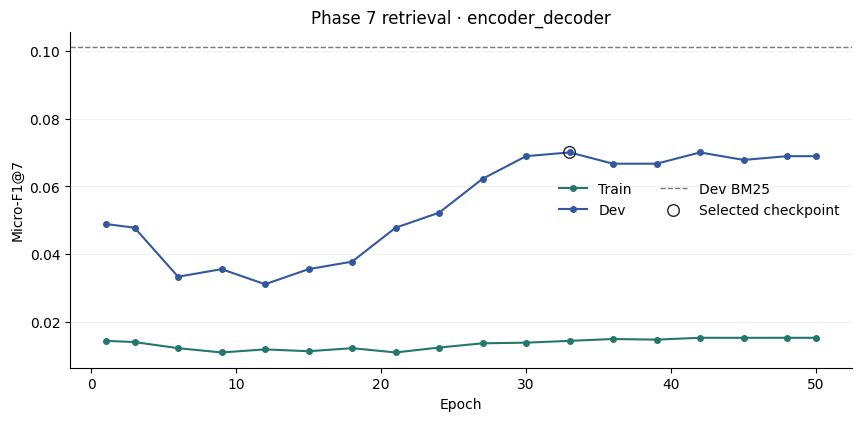

In [7]:
import matplotlib.pyplot as plt

record = read_json(RUN_DIR / "metrics.json")
records = pd.DataFrame([
    {"Epoch": row["epoch_position"], "Update": row["optimizer_updates"], "Check": row["kind"],
     "Train F1@7": row["train"]["micro_f1_at_7"], "Dev F1@7": row["dev"]["micro_f1_at_7"],
     "Gap": row["train_dev_gap"], "Best Dev": row["best_dev_f1_at_7"],
     "Checks since best": row["checks_without_improvement"]}
    for row in record["evaluations"]
])
display(records.style.format({"Epoch": "{:.2f}", "Train F1@7": "{:.4f}", "Dev F1@7": "{:.4f}",
                              "Gap": "{:+.4f}", "Best Dev": "{:.4f}"}).hide(axis="index"))
if not records.empty:
    best = result["best"]
    fig, ax = plt.subplots(figsize=(8.5, 4.1), layout="constrained")
    ax.plot(records["Epoch"], records["Train F1@7"], color="#24776c", marker="o", ms=4, label="Train")
    ax.plot(records["Epoch"], records["Dev F1@7"], color="#3458a0", marker="o", ms=4, label="Dev")
    ax.axhline(data.bm25_metrics["dev"]["micro_f1_at_7"], ls="--", lw=1,
               color="#777777", label="Dev BM25")
    ax.scatter(best["epoch_position"], best["dev"]["micro_f1_at_7"], s=70,
               facecolors="none", edgecolors="#20252d", zorder=4, label="Selected checkpoint")
    ax.set(xlabel="Epoch", ylabel="Micro-F1@7", title=f"Phase 7 retrieval · {ARCHITECTURE}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=.18)
    ax.legend(frameon=False, ncols=2)
    fig.savefig(RUN_DIR / "f1_history.png", dpi=160, bbox_inches="tight")
    plt.show()

## 8. Run artifacts and teacher handoff

Upload `submission.zip` for the selected run. Its root contains `prediction.json`, which maps every test query ID to seven ranked candidate IDs with the original string formatting.

Keep `best_model.pt`, `best_model.json` and `metrics.json` from the three larger runs. The tensor file stores the selected trainable EMA weights. To reconstruct a teacher, initialize the same Phase 1 checkpoint and retrieval architecture, then load the EMA tensors by parameter name using the metadata. Choose the teacher using completed Dev scores. Retain the gold student's metrics for comparison with its distilled counterpart.

To finish a Test export that ran out of active time, set `EXPORT_ONLY = True` and run again with the same inputs and recovery state. This mode runs inference in a separate pass.

In [8]:
best = result["best"]
print(f"Selected epoch {best['epoch_position']:.2f} · "
      f"Train Micro-F1@7 {best['train']['micro_f1_at_7']:.4f} · "
      f"Dev Micro-F1@7 {best['dev']['micro_f1_at_7']:.4f}")
print(f"Stop reason · {result['stop_reason']} | Active time · {result['active_minutes']:.1f} min")
artifacts = {
    "submission.zip": "Upload-ready Test archive",
    "prediction.json": "Ranked Test candidate IDs",
    "best_model.pt": "Selected EMA weights",
    "best_model.json": "Checkpoint identity and reconstruction settings",
    "dev_prediction.json": "Selected checkpoint's Dev ranking",
    "metrics.json": "BM25 reference, epoch loss and paired checks",
    "f1_history.png": "Training and Dev F1 plot",
    "recovery/": "Latest recovery states and verification receipts",
}
display(pd.DataFrame([
    {"Artifact": name, "Contents": description, "Path": str(RUN_DIR / name)}
    for name, description in artifacts.items() if (RUN_DIR / name).exists()
]).style.hide(axis="index"))

Selected epoch 33.00 · Train Micro-F1@7 0.0144 · Dev Micro-F1@7 0.0700
Stop reason · epoch_limit | Active time · 274.6 min


Artifact,Contents,Path
submission.zip,Upload-ready Test archive,/kaggle/working/cs781_phase7/runs/encoder_decoder_gold/submission.zip
prediction.json,Ranked Test candidate IDs,/kaggle/working/cs781_phase7/runs/encoder_decoder_gold/prediction.json
best_model.pt,Selected EMA weights,/kaggle/working/cs781_phase7/runs/encoder_decoder_gold/best_model.pt
best_model.json,Checkpoint identity and reconstruction settings,/kaggle/working/cs781_phase7/runs/encoder_decoder_gold/best_model.json
dev_prediction.json,Selected checkpoint's Dev ranking,/kaggle/working/cs781_phase7/runs/encoder_decoder_gold/dev_prediction.json
metrics.json,"BM25 reference, epoch loss and paired checks",/kaggle/working/cs781_phase7/runs/encoder_decoder_gold/metrics.json
f1_history.png,Training and Dev F1 plot,/kaggle/working/cs781_phase7/runs/encoder_decoder_gold/f1_history.png
recovery/,Latest recovery states and verification receipts,/kaggle/working/cs781_phase7/runs/encoder_decoder_gold/recovery


## References and provenance

- CS781 Capstone §13, *Prior Case Retrieval*. Split-local candidate pools, submission schema and Micro-F1@7.
- Karpukhin et al. (2020), [Dense Passage Retrieval](https://aclanthology.org/2020.emnlp-main.550/).
- Liu et al. (2022), [IA³](https://arxiv.org/abs/2205.05638).
- The user's Phase 1 legal models and Phase 7 preparation notebook. Input and source identities are recorded with each run.
- [Official CS781 dataset](https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone)